# Beyond: the UF as its own currency and a test that catches a behavioural assumption changed at a limit breach

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 01 to 07 of this topic
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- state the two claims of this topic, BS-7 (the UF as its own currency in IRRBB) and BS-8 (a test that flags a behavioural assumption changed at a limit breach), the committed evidence for each, the practice each goes beyond, and the limit of each claim;
- show, with the engine, what a single-currency treatment of the UF would lose compared with Annex 1 (sizes, floor, offset and charge);
- run the breach test on controlled histories and on the committed parameters, and say what it discriminates and what it does not;
- say what a validator does with a red result of this test;
- compare each recomputation with the committed value, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import eve_nii, shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

Two cases feed the two claims.

- **BS-7** reads case C15, the **synthetic** Banco Andino on a CLP and UF balance sheet at 2026-09-03, in four of its six variants: `short-uf`, `long-uf`, `offset-on-off` and `floors-active`. The balance-sheet aggregates are calibrated to the CMF system figures of August 2026 (https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf, public statistics, licence class `mirror-allowed`); the curves are the real yields of the Banco Central de Chile (BDE table F022, `mirror-allowed`). Money is in CLP millions.
- **BS-8** reads case C14, the bank that failed in March 2023, at the valuation dates 2021-Q4, 2022-Q2 and 2022-Q4: the FDIC call reports (https://api.fdic.gov/banks/financials) and the US Treasury par curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), public-domain sources of the licence class `mirror-allowed`. The bank is **real in aggregate and synthetic in behaviour**: the share and the maturity of the stable deposits are stated by Contraste, and the replicating-portfolio maturity is fitted on the report history. Money is in USD thousands.

A positive delta EVE or delta NII is a loss in both.

- **Files read:** `data/derived/C15/short-uf.json`, `long-uf.json`, `offset-on-off.json` and `floors-active.json` (`outputs.legs`, `curves`, `eve`, `nii`, `floors`, `offset_rule`, `indexation_charge`, `thresholds`), `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` and `vd-2022-q4.json` (`outputs.nmd_segments`, `scenarios`; `tests`) and `data/derived/C14/models-svb-2021-2022.json` (`fit.nmd_models`, `nmd_parameter_changes`).

The next cell loads the files and prints the engine version that baked them.

In [2]:
# Load the four C15 variants, the three C14 valuation dates and the C14 model document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
variants = {v: json.loads((ROOT / "data" / "derived" / "C15" / f"{v}.json").read_text(encoding="utf-8")) for v in ("short-uf", "long-uf", "offset-on-off", "floors-active")}
docs = {q: json.loads((ROOT / "data" / "derived" / "C14" / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in ("2021-Q4", "2022-Q2", "2022-Q4")}
fit = json.loads((ROOT / "data" / "derived" / "C14" / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
# Names of the document's own values in this language (the identifiers of the file stay as they are)
NAME = {"parallel-up": "parallel up", "parallel-down": "parallel down", "steepener": "steepener",
        "flattener": "flattener", "short-up": "short up", "short-down": "short down", True: "yes", False: "no"}
for v, d in variants.items():
    print(f"C15 {v:14s} | baked by riskvalidation {d['provenance']['riskvalidation_version']} | installed {rv.__version__}")
for q, d in docs.items():
    print(f"C14 {q:14s} {d['outputs']['valuation_date']} | baked by riskvalidation {d['provenance']['riskvalidation_version']} | installed {rv.__version__}")

C15 short-uf       | baked by riskvalidation 0.9.0 | installed 0.9.0
C15 long-uf        | baked by riskvalidation 0.9.0 | installed 0.9.0
C15 offset-on-off  | baked by riskvalidation 0.9.0 | installed 0.9.0
C15 floors-active  | baked by riskvalidation 0.9.0 | installed 0.9.0
C14 2021-Q4        2021-12-31 | baked by riskvalidation 0.9.0 | installed 0.9.0
C14 2022-Q2        2022-06-30 | baked by riskvalidation 0.9.0 | installed 0.9.0
C14 2022-Q4        2022-12-31 | baked by riskvalidation 0.9.0 | installed 0.9.0


## Method

The notebook states each claim, shows the evidence of the committed files with the engine, and shows a control or a counterfactual that makes the claim testable: for BS-7 the cost of not treating the UF as a currency, for BS-8 histories where the test must be green and where it must be red. Each claim ends with its limit. The claims and their evidence are stated in the SDD's section `## Beyond the state of the art`; the notebook does not state more than the SDD does.

- **BS-7.** The reajustabilidad risk of RAN 21-13 Annex 1 as a separate currency (the UR) with its own shocks, floor, the indexation charge (2.5 percent of the absolute net UF position) and the 50 percent offset of the peso delta against the UR delta. Evidence: `data/derived/C15/long-uf.json`, `floors-active.json`, `offset-on-off.json`.
- **BS-8.** The test `irrbb.behavioural_change_at_breach`, which turns a finding of the Federal Reserve's review of the failed bank into a validation test. Evidence: the committed rows of `data/derived/C14/vd-2022-q2.json`.

## State of the art

**For BS-7.** The Basel standard has 21 currencies in its shock table and a rule for aggregating them; it has no unit like the UF, an indexed unit of account whose value in the local currency follows inflation, and no currency of the local jurisdiction that is missing from the table gets a size (SRP31.90, Table 2; BCBS d578, https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf). The Chilean regulator's Annex 1 of chapter 21-13 (https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf) fills that gap with the UR. The research found the Chilean approach described as "a genuine differentiator" (dossier 03, F.2) and found no public implementation of the Annex; that is a finding of the dossier's search and stays **UNVERIFIED** beyond it. The claim is regional, not global.

**For BS-8.** The Federal Reserve's review of Silicon Valley Bank states the practice as a finding: the bank "had breached its long-term IRR limits on and off since 2017" and "in April 2022 ... made counterintuitive modeling assumptions about the duration of deposits to address the limit breach rather than managing the actual risk" (https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf; dossier 05, D.7). The research proposes the test ("a Contraste validation test should therefore flag any change in NMD behavioural parameters that coincides with a limit breach") and cites no tool that implements it.

The first cell below shows the first fact for BS-7 with the engine: the Basel table has no entry for the peso or for the UF, and the engine refuses a size for them instead of inventing one.

In [3]:
# The Basel table has no entry for the peso or the UF: the engine refuses a size; the Chilean table has both
for calibration in ("2016", "2024"):
    table = shocks.shock_table(calibration)
    print(calibration, "| currencies:", len(table), "| CLP:", NAME["CLP" in table], "| CLF:", NAME["CLF" in table])
for currency in ("CLP", "CLF"):
    try:
        shocks.shock_size(currency, "2024")
    except ValueError as error:
        print(currency, "refused:", str(error)[:80], "...")
for currency in ("CLP", "CLF"):
    z = shocks.shock_size(currency, "cmf-annex1")
    print(f"{currency} cmf-annex1: {z.parallel_bp:.0f}/{z.short_bp:.0f}/{z.long_bp:.0f} bp | origin {z.origin}")

2016 | currencies: 21 | CLP: no | CLF: no
2024 | currencies: 21 | CLP: no | CLF: no
CLP refused: CLP has no shock size under 2024: supply the size with its label and method (a s ...
CLF refused: CLF has no shock size under 2024: supply the size with its label and method (a s ...
CLP cmf-annex1: 300/400/200 bp | origin cmf-annex1
CLF cmf-annex1: 200/250/150 bp | origin cmf-annex1


## Beyond the state of the art

### BS-7: the UF as its own currency

**What the claim adds.** Annex 1 of chapter 21-13 treats the reajustabilidad risk as a separate currency with its own shocks, its own floor, the indexation charge and the 50 percent offset; the engine implements it, and the committed C15 variants recompute from it. The first cell shows the separation in the committed documents: the sizes and the floor of each currency and the curve each one is discounted on. The second shows why the floor must be the currency's own: the UR curve is a real-rate curve, around 1.2 to 2.8 percent, and a downward shock of 200 bp pushes its short end below zero, where the peso floor of 0 percent would bind in nine bands and the UR floor of -2 percent in none.

In [4]:
# The sizes, the floor and the curve of each currency in the committed documents, and the engine's size for each
out = variants["short-uf"]["outputs"]
rates = {"CLP": np.array(out["curves"]["clp"]["zero_rates_at_midpoints"]), "UR": np.array(out["curves"]["ur"]["zero_rates_at_midpoints"])}
floors = {"CLP": out["floors"]["other_floor"], "UR": out["floors"]["ur_floor"]}
print(f"{'':4s} {'EVE sizes (par/short/long)':>40s} {'NII size':>14s} {'floor':>8s} {'rate, band 1':>16s} {'rate, band 19':>17s}")
for committed in out["eve_shock_sizes"]:
    leg = "CLP" if committed["currency"] == "CLP" else "UR"
    nii = next(x["parallel_bp"] for x in out["nii_shock_sizes"] if x["currency"] == committed["currency"])
    z = shocks.shock_size(committed["currency"], "cmf-annex1")
    same = (z.parallel_bp, z.short_bp, z.long_bp) == (committed["parallel_bp"], committed["short_bp"], committed["long_bp"])
    print(f"{leg:4s} {committed['parallel_bp']:.0f}/{committed['short_bp']:.0f}/{committed['long_bp']:.0f}{'':>26s} {nii:14.0f} {floors[leg]:8.2f} {rates[leg][0]:16.5f} {rates[leg][18]:17.5f}  equal to the engine {NAME[same]}")

                   EVE sizes (par/short/long)       NII size    floor     rate, band 1     rate, band 19
CLP  300/400/200                                      300     0.00          0.04499           0.05911  equal to the engine yes
UR   200/250/150                                      300    -0.02          0.01205           0.02839  equal to the engine yes


Now the floor. The next cell applies a 200 bp fall to the UR curve of the first variant with the peso floor and then with the UR floor, and lists the bands where each floor binds.

In [5]:
# Apply a 200 bp fall to the UR curve with the peso floor (0) and with the UR floor (-2 percent) and count the bands where the floor binds
raw = shocks.apply_floor(rates["UR"], np.full(19, -200.0), None)
for label, floor in (("peso floor (0)", 0.0), ("UR floor (-2 percent)", -0.02)):
    bound = [int(k) + 1 for k in np.flatnonzero(~np.isclose(shocks.apply_floor(rates["UR"], np.full(19, -200.0), floor), raw))]
    print(f"{label:34s} bands where it binds: {bound}")
print("lowest rate of the UR curve after -200 bp, before the floor:", round(float(raw.min()), 5))

peso floor (0)                     bands where it binds: [1, 2, 3, 4, 5, 6, 7, 8, 9]
UR floor (-2 percent)              bands where it binds: []
lowest rate of the UR curve after -200 bp, before the floor: -0.00795


**The counterfactual: what a single-currency treatment loses.** Without the UR, a bank would put its UF flows, converted to pesos, with the peso flows, discount them all on the peso curve, shock them with the peso sizes and the zero floor, and add no charge: one currency. The cell does exactly that with the engine for the four variants, using the committed net flows of each leg, and compares the two measures and the ratios to Tier 1. It is a counterfactual, not a rival method: it shows what is lost when the UF is not a currency of its own. The difference has four parts that act together, the curve (nominal instead of real), the sizes (peso sizes for the UF flows), the full netting of the legs inside a single sum, and the missing charge.

In [6]:
# Annex 1 measures against a single-currency treatment of the same flows: peso curve, peso sizes, zero floor, no charge
peso = shocks.shock_size("CLP", "cmf-annex1")
compare = {}
print(f"{'':14s} {'ΔEVE Annex':>11s} {'ΔEVE single':>12s} {'ΔNII Annex':>11s} {'ΔNII single':>12s} {'ΔNII charge':>12s} {'ΔEVE/T1 Annex, single':>26s} {'ΔNII/T1 Annex, single':>26s}")
for v, d in variants.items():
    o = d["outputs"]
    uf = o["ur_currency"]["uf_value"]
    base = {}
    for leg in o["legs"]:
        vector = np.zeros(19)
        for item in leg["items"]:
            for row in item["cash_flows"]:
                vector[row["bucket"] - 1] += row["amount"]
        base[leg["leg"]] = vector * (1.0 if leg["leg"] == "CLP" else uf)
    r_peso = np.array(o["curves"]["clp"]["zero_rates_at_midpoints"])
    total = base["CLP"] + base["UR"]
    loss_eve = []
    for row in o["eve"]["rows"]:
        net = np.array(row["clp"]["net_cash_flows"]) + np.array(row["ur"]["net_cash_flows"])
        shocked = shocks.apply_floor(r_peso, shocks.shock_curve(row["shock"], peso.parallel_bp, peso.short_bp, peso.long_bp, MID), 0.0)
        loss_eve.append(eve_nii.delta_eve(total, net, r_peso, shocked, MID))
    loss_nii = [eve_nii.delta_nii(total, r_peso, shocks.apply_floor(r_peso, np.full(19, bp), 0.0), MID) for bp in (300.0, -300.0)]
    single_eve, single_nii = max(0.0, max(loss_eve)), max(0.0, max(loss_nii))
    annex_eve, annex_nii, tier1 = o["eve"]["delta_eve"], o["nii"]["delta_nii"], o["thresholds"]["tier1"]
    compare[v] = (annex_eve / tier1, single_eve / tier1, annex_nii / tier1, single_nii / tier1)
    print(f"{v:14s} {annex_eve:11,.0f} {single_eve:12,.0f} {annex_nii:11,.0f} {single_nii:12,.0f} {o['nii']['indexation_charge']:12,.0f} {annex_eve / tier1:12.4f} {single_eve / tier1:12.4f} {annex_nii / tier1:12.4f} {single_nii / tier1:12.4f}")

                ΔEVE Annex  ΔEVE single  ΔNII Annex  ΔNII single  ΔNII charge      ΔEVE/T1 Annex, single      ΔNII/T1 Annex, single
short-uf            79,643       64,213      11,067        1,356        6,182       0.0966       0.0779       0.0134       0.0016
long-uf             93,816       84,710      11,213        1,648        6,182       0.1138       0.1028       0.0136       0.0020
offset-on-off       81,173       59,422      11,016        1,254        6,182       0.0985       0.0721       0.0134       0.0015
floors-active       60,764       49,837       6,606        4,653        1,030       0.0737       0.0605       0.0080       0.0056


**The offset and the charge.** The offset rule gives half credit to the gain leg when the two deltas have opposite signs. The `offset-on-off` variant holds the pair with and without the offset, and the same engine functions give the Annex measures both ways for the four variants. The charge is added once to the delta NII whatever the offset. The next cell prints both measures with and without the offset, the share of the delta NII that is the charge, and the closest approach of any post-shock rate to its floor.

In [7]:
# The Annex measures with and without the offset, the charge as a share of the delta NII, and the closest approach to a floor
print(f"{'':14s} {'ΔEVE offset':>14s} {'ΔEVE no offset':>16s} {'ΔNII offset':>14s} {'ΔNII no offset':>16s} {'charge/ΔNII':>14s} {'closest floor (bp)':>22s}")
for v, d in variants.items():
    o = d["outputs"]
    d_clp, d_ur = (np.array([r[leg]["delta_eve"] for r in o["eve"]["rows"]]) for leg in ("clp", "ur"))
    n_clp, n_ur = (np.array([r[leg]["delta_nii"] for r in o["nii"]["rows"]]) for leg in ("clp", "ur"))
    eve_on, eve_off = (eve_nii.annex1_delta_eve(d_clp, d_ur, flag) for flag in (True, False))
    nii_on, nii_off = (eve_nii.annex1_delta_nii(n_clp, n_ur, o["indexation_charge"]["pn_ur"], flag) for flag in (True, False))
    closest = min(x["distance_bp"] for x in o["floors"]["distances"])
    print(f"{v:14s} {eve_on.delta_eve:14,.0f} {eve_off.delta_eve:16,.0f} {nii_on.delta_nii:14,.0f} {nii_off.delta_nii:16,.0f} {nii_on.indexation_charge / nii_on.delta_nii:14.4f} {closest:22.2f}")

                  ΔEVE offset   ΔEVE no offset    ΔNII offset   ΔNII no offset    charge/ΔNII     closest floor (bp)
short-uf               79,643           79,643         11,067           14,597         0.5586                  20.48
long-uf                93,816           94,721         11,213           14,597         0.5513                  20.48
offset-on-off          81,173           94,721         11,016           14,597         0.5612                  20.48
floors-active          60,764           60,764          6,606            7,528         0.1560                  20.48


**The limit of BS-7.** The evidence shows that the engine implements Annex 1 as a separate currency and that the committed variants recompute from it. It does not show that the Annex is applied the way the CMF applies it: there is no second implementation to reconcile with, and the dossier's search found none (UNVERIFIED beyond that search). The floors are implemented and tested but never bind on the committed curves, the closest being 20.48 bp away, so their effect on a number is not demonstrated by this data. The bank is synthetic. And the claim is regional: the standard has no UF-like unit, and only Chile's Annex needs one here.

### BS-8: a test that flags a behavioural assumption changed at a limit breach

**What the claim adds.** `irrbb.behavioural_change_at_breach` takes the series of a behavioural parameter, the dates and a breach flag per date, and counts the dates where the parameter changed and the flag is true. It is red at one or more, green at none, and `not_evaluated` with fewer than two dates. The first cell shows that the test discriminates, on five constructed histories whose answer is known: a parameter held fixed through a breach, a parameter that changes with no breach, a parameter changed at a breach, a parameter changed before the breach but not at it, and a single date. These are constructed numbers that exercise the rule, not data of any bank.

In [8]:
# Five constructed histories with a known answer: fixed under a breach, changed with no breach, changed at a breach, changed before it, one date
days = np.array(["2021-12-31", "2022-06-30", "2022-12-31"], dtype="datetime64[D]")
cases = [
    ("fixed through a breach", [4.0, 4.0, 4.0], [True, True, True], days),
    ("changed, no breach", [4.0, 4.5, 5.0], [False, False, False], days),
    ("changed at a breach", [4.0, 4.0, 4.5], [False, False, True], days),
    ("changed before the breach", [4.0, 4.5, 4.5], [False, False, True], days),
    ("a single date", [4.0], [True], days[:1]),
]
print(f"{'':36s} {'values':>16s}  {'breach flags':>40s}  light   flagged dates")
for label, values, flags, when in cases:
    run = rv_irrbb.behavioural_change_at_breach(np.array(values), when, np.array(flags, dtype=bool))
    print(f"{label:36s} {str(values):>16s}  {str([NAME[f] for f in flags]):>40s}  {run.light.value:13s} {run.extras.get('flagged_dates', [])}")

                                               values                              breach flags  light   flagged dates
fixed through a breach                [4.0, 4.0, 4.0]                     ['yes', 'yes', 'yes']  green         []
changed, no breach                    [4.0, 4.5, 5.0]                        ['no', 'no', 'no']  green         []
changed at a breach                   [4.0, 4.0, 4.5]                       ['no', 'no', 'yes']  red           ['2022-12-31']
changed before the breach             [4.0, 4.5, 4.5]                       ['no', 'no', 'yes']  green         []
a single date                                   [4.0]                                   ['yes']  not_evaluated []


**The evidence on the committed bank.** The committed model document lists, for two consecutive pairs of dates, the behavioural parameters of the wholesale deposits and whether each changed: the core share and the core maturity that Contraste requests (stated, synthetic) and the weighted average maturity of the fitted replicating portfolio. The cell runs the engine test on the three series of the three dates with the breach flag of each date from the committed scenarios, and compares the flagged dates with the committed `nmd_parameter_changes`. Then it runs the same test on the average maturity with the breach flags all set to false, as a control: the verdict is decided by the flag, not by the movement alone.

In [9]:
# Run the breach test on the three parameters of the wholesale deposits at the three dates, against the committed changes, and a control with no breach
dates = np.array([d["outputs"]["valuation_date"] for d in docs.values()], dtype="datetime64[D]")
breach = np.array([bool(d["outputs"]["scenarios"][0]["outlier"]["breached"]) for d in docs.values()])
wholesale = [next(s for s in d["outputs"]["nmd_segments"] if s["category"] == "wholesale") for d in docs.values()]
wam = [next(m for m in fit["nmd_models"] if m["valuation_date"] == str(day))["weighted_average_maturity_years"] for day in dates]
series = {
    "requested core share": [s["requested_core_share"] for s in wholesale],
    "requested core maturity (y)": [s["requested_core_maturity_years"] for s in wholesale],
    "fitted average maturity (y)": wam,
}
print("dates:", [str(x) for x in dates], "| breach flags:", [NAME[bool(b)] for b in breach])
for name, values in series.items():
    run = rv_irrbb.behavioural_change_at_breach(np.array(values), dates, breach)
    print(f"{name:52s} {[round(v, 4) for v in values]} -> light {run.light.value:5s} flagged {run.extras['flagged_dates']}")
control = rv_irrbb.behavioural_change_at_breach(np.array(wam), dates, np.zeros(3, dtype=bool))
print("control: the same fitted maturity with no breach -> light", control.light.value)
flagged_committed = sorted({c["to_date"] for c in fit["nmd_parameter_changes"] if c["flagged"]})
print("dates flagged in the committed changes:", flagged_committed, "| equal to the engine's on the fitted maturity:", NAME[flagged_committed == run.extras["flagged_dates"]])

dates: ['2021-12-31', '2022-06-30', '2022-12-31'] | breach flags: ['yes', 'yes', 'yes']
requested core share                                 [0.6, 0.6, 0.6] -> light green flagged []
requested core maturity (y)                          [5.0, 5.0, 5.0] -> light green flagged []
fitted average maturity (y)                          [4.7595, 4.2049, 5.0] -> light red   flagged ['2022-06-30', '2022-12-31']
control: the same fitted maturity with no breach -> light green
dates flagged in the committed changes: ['2022-06-30', '2022-12-31'] | equal to the engine's on the fitted maturity: yes


The committed rows at the three dates are the same test with the history up to each date (notebook 05). At 2022-Q2 the row is red with the note "1 change(s) coincide with a breach", at 2022-Q4 it is red with two. The next cell prints them, and the `irrbb.eve_with_without_behavioural` row beside each, because the claim is that the two together are what the review of the failed bank taught.

In [10]:
# The committed breach-test row and with-and-without row at the three dates, with the engine version that baked them
for q, d in docs.items():
    breach_row = next(t for t in d["tests"] if t["test_id"] == "irrbb.behavioural_change_at_breach")
    both_row = next(t for t in d["tests"] if t["test_id"] == "irrbb.eve_with_without_behavioural")
    print(f"{q}: breach test {breach_row['light']:13s} | {breach_row['notes'] or '-'} | with and without {both_row['light']} | baked by riskvalidation {d['provenance']['riskvalidation_version']}")

2021-Q4: breach test not_evaluated | not evaluated: fewer than 2 dates | with and without red | baked by riskvalidation 0.9.0
2022-Q2: breach test red           | 1 change(s) coincide with a breach | with and without red | baked by riskvalidation 0.9.0
2022-Q4: breach test red           | 2 change(s) coincide with a breach | with and without red | baked by riskvalidation 0.9.0


**The limit of BS-8.** The red row is not a finding about the bank. In C14 the bank's outlier test is breached at the three dates, so the breach flag never varies; the parameter that moves is the fitted replicating-portfolio maturity, which is re-estimated at each date and therefore differs by construction, while the two parameters Contraste states are held fixed and are not flagged. What the evidence shows is that the test separates a stated assumption held through a breach from a series that moves while the limit is breached, and that its verdict is decided by the breach flag; the same series with no breach is green. It does not show that anyone chose the fitted maturity to relieve a breach, and the bank's behaviour is synthetic. A red is a prompt for the validator to ask who moved the parameter, when, why, and with what approval, and whether the new value is supported by the data; the first answers are in the model-governance record, not in the test.

The last cell draws both claims. On the left, the Annex 1 measure against the single-currency counterfactual for the four variants, as a share of Tier 1, for the delta EVE and the delta NII. On the right, the fitted average maturity of the wholesale deposits at the three dates, with the breach marks and the dates the test flags.

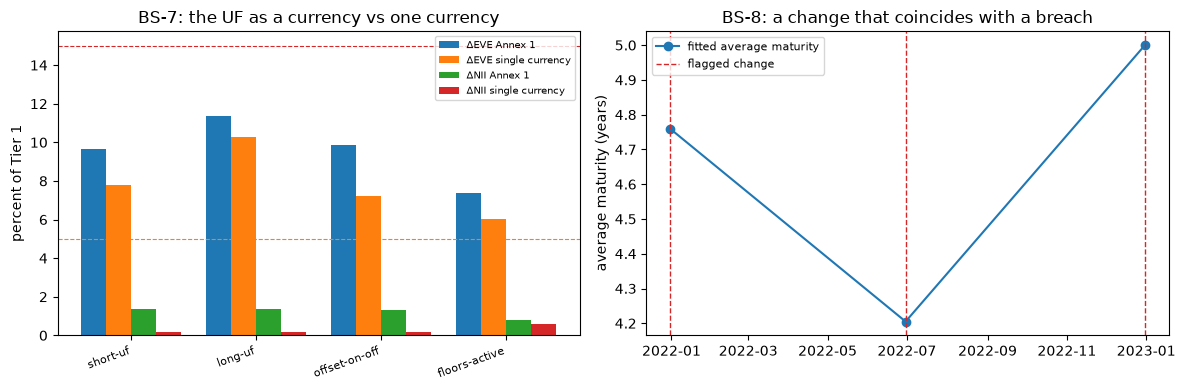

In [11]:
# Draw the Annex 1 measures against the single-currency counterfactual, and the fitted maturity with the flagged dates
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
names = list(compare)
x = np.arange(len(names))
left.bar(x - 0.3, [compare[v][0] * 100 for v in names], 0.2, label="ΔEVE Annex 1")
left.bar(x - 0.1, [compare[v][1] * 100 for v in names], 0.2, label="ΔEVE single currency")
left.bar(x + 0.1, [compare[v][2] * 100 for v in names], 0.2, label="ΔNII Annex 1")
left.bar(x + 0.3, [compare[v][3] * 100 for v in names], 0.2, label="ΔNII single currency")
left.axhline(15, color="tab:red", linestyle="--", linewidth=0.8)
left.axhline(5, color="tab:orange", linestyle="--", linewidth=0.8)
left.set_xticks(x)
left.set_xticklabels(names, rotation=20, ha="right", fontsize=8)
left.set_ylabel("percent of Tier 1")
left.set_title("BS-7: the UF as a currency vs one currency")
left.legend(fontsize=7)
run = rv_irrbb.behavioural_change_at_breach(np.array(wam), dates, breach)
right.plot(dates, wam, marker="o", color="tab:blue", label="fitted average maturity")
for day in run.extras["flagged_dates"]:
    right.axvline(np.datetime64(day), color="tab:red", linestyle="--", linewidth=1)
right.axvline(dates[0], color="tab:red", linestyle="--", linewidth=1, label="flagged change")
right.set_ylabel("average maturity (years)")
right.set_title("BS-8: a change that coincides with a breach")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **BS-7, the separation.** Neither Basel table has the peso or the UF (21 currencies each), and the engine refuses a size for them. The Chilean table gives the peso 300/400/200 bp and the UR 200/250/150 bp for the EVE and 300 bp for the NII, and the committed documents carry each currency on its own curve: 4.50 percent in the first band for the peso and 1.21 percent for the UR. The floor has to be the currency's own: a 200 bp fall takes the UR curve to -0.795 percent in the first band, and the peso floor of 0 percent would bind in nine bands while the UR floor of -2 percent binds in none.
- **BS-7, what a single currency loses.** Treating the UF flows as pesos (peso curve, peso sizes, zero floor, no charge, one sum) gives, for the short-UF, long-UF and offset-on-off variants, a delta NII of 1,356, 1,648 and 1,254 against the Annex 1 values of 11,067, 11,213 and 11,016: 6.8 to 8.8 times smaller. The delta EVE is 64,213, 84,710 and 59,422 against 79,643, 93,816 and 81,173: 10 to 27 percent smaller. In the floors-active variant, with a net UF position of 5 percent of Tier 1, the gap is smaller (4,653 against 6,606 for the NII). The ratio to Tier 1 does not cross a line in either treatment in these four variants, so the claim is not that a bank would pass or fail differently, but that the measure the regulator defines is not the one a single-currency calculation gives.
- **BS-7, the offset and the charge.** The offset lowers the delta NII from 14,597 to 11,067 in the short-UF variant (24 percent) and the delta EVE from 94,721 to 81,173 in the offset-on-off variant (14 percent); in the short-UF variant it does not change the delta EVE, because the worst shock has both legs losing. The charge is 55.9, 55.1 and 56.1 percent of the delta NII in the three variants with a net UF position of 30 percent of Tier 1, and 15.6 percent in the one with 5 percent.
- **BS-7, the limit.** The floors never bind: the closest post-shock rate is 20.48 bp from its floor in the four variants, so their effect on a number is not demonstrated here. There is no second implementation of Annex 1 to reconcile with; the dossier's search found none, which stays unverified beyond it. The bank is synthetic, and the claim is regional.
- **BS-8, the discrimination.** On the five constructed histories the test gives the verdict the rule says: green for a parameter held fixed through a breach, green for a change with no breach, green for a change before the breach, red for a change at the breach (flagging 2022-12-31), and not evaluated for a single date.
- **BS-8, the committed bank.** On the committed parameters the requested core share (0.6) and the requested core maturity (5 years) do not change and the test is green; the fitted average maturity moves, 4.7595, 4.2049 and 5.0 years, and the test is red at 2022-06-30 and 2022-12-31, the same dates as the committed changes. With the breach flags set to false, the same series is green: the breach flag decides. The committed rows are red at 2022-Q2 (one change) and 2022-Q4 (two), and not evaluated at 2021-Q4; the with-and-without test of the EVE is red at the three dates.
- **BS-8, the limit.** The outlier test is breached at the three dates, so the flag never varies, and the parameter that moves is a fitted one that is re-estimated at each date, so it differs by construction. The red is therefore not a finding that anyone tuned the maturity to relieve a breach; it shows that the test operates on those parameters and would do so on a parameter that a manager changed. What a validator does with a red: ask who moved the parameter, when and with what approval; compare the new value with the data that support it (notebook 05 shows that the fitted weights are not stable across windows); and read the EVE with and without behaviour at the same date. The bank's behaviour is synthetic.
- **What the notebook does not show.** A reconciliation of the Chilean figures with a second implementation, the effect of a floor on a number, and a case where a manager changed a stated assumption at a breach: the committed data has none.

## Summary

- BS-7: the Chilean Annex treats the UF as a currency of its own; the engine implements its sizes, floor, offset and charge, and the committed variants recompute from it. A single-currency treatment of the same flows would give a very different delta NII, because the charge and the pairing are what make the NII measure.
- BS-7 has limits: no second implementation to reconcile with, floors that never bind on these curves, a synthetic bank, and a regional claim.
- BS-8: the breach test is red when a parameter changes at a date with a breach and green otherwise, and the verdict is decided by the breach flag.
- BS-8 has limits: in the committed bank every date is a breach and the parameter that moves is a fitted one, so the red shows that the test operates, not that the bank did what the review of the failed bank found.
- Both claims are stated in the SDD only as far as this evidence goes.

**What to try next.** Change the breach flags of the constructed histories and write down which verdict follows which rule. Then read the claims in the SDD's section `## Beyond the state of the art` against this notebook.

## References

- CMF, Recopilacion Actualizada de Normas, chapter 21-13, Annex 1 (the UR, the sizes, the floors, the offset and the charge). https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 (the shock sizes) and SRP31.129. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book. https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- CMF, Informe del Desempeno del Sistema Bancario y Cooperativas, August 2026. https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf
- FDIC, BankFind financials, public domain. https://api.fdic.gov/banks/financials
- US Department of the Treasury, Daily Treasury Par Yield Curve Rates, public domain. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 03 (Chile, section F.2) and dossier 05 (section D.7) of the Contraste research; the SDD section `## Beyond the state of the art`.